# TP 1 RL : Dynamic programing

L'objectif de ce TP est de se familiariser avec la programmation dynamique pour le calcul de fonction de valeur d'état et de politique. Nous nous commencerons avec un environnement très simple : un griddworld de taille $10\times 10$.

**La programmation dynamique (Dynamic Programming ou DP)** est une famille d'algorithmes utilisés en apprentissage par renforcement pour calculer la valeur des états et déterminer une politique optimale lorsque le modèle de l'environnement est connu.

GRIDE WORLD

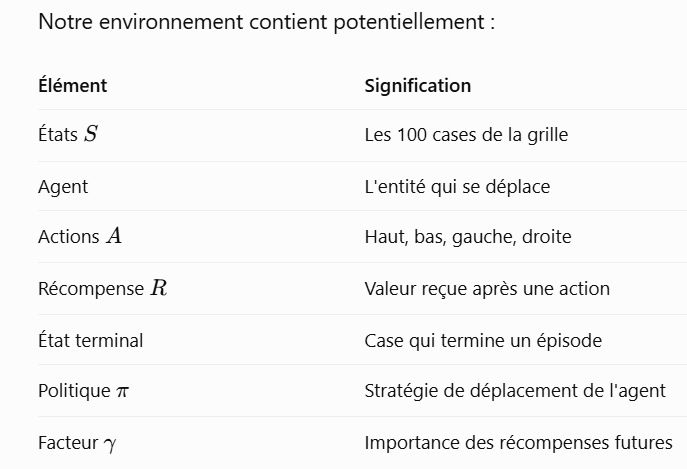

In [5]:
# Bloc 1 : Importation des bibliothèques

import numpy as np                    # Calculs numériques
from matplotlib import pyplot as plt   # Visualisation graphique
from time import sleep                # Pause d'exécution
from IPython.display import clear_output # Actualisation de l'affichage
import math                           # Fonctions mathématiques
import numpy.matlib                   # Manipulation des matrices
import imageio                        # Gestion des images et animations

In [6]:
#@title Utils functions

def plot_pi(pi):
  plt.xticks(np.arange(-1, N+1, 1))
  plt.yticks(np.arange(-1, N+1, 1))
  plt.grid( which='major')

  param = {'lw':3,
           'head_width':2/N}
  for i in range(pi.shape[0]):
    ll = pi[i,:]
    x = i%N
    y = N - math.ceil((i+1)/N)
    args = np.argwhere(ll>0)
    for n in args:
      if n==0:
        plt.arrow(x,y,.5,0,**param)
      elif n==1:
        plt.arrow(x,y,0,.5,**param)
      elif n==2:
        plt.arrow(x,y,-.5,0,**param)
      elif n==3:
        plt.arrow(x,y,0,-.5,**param)

def get_next_Vij(V_2d,i,j):
  if i<0 or i>N or j<0 or j>N:
    raise ValueError("indices must be between 0 and N")
  if i==0:
    if j==N-1:
      ll = (-1e3,-1e3,V_2d[i,j-1],V_2d[i+1,j])
    else:
      ll = (V_2d[i,j+1],-1e3,V_2d[i,j-1],V_2d[i+1,j])
  elif j==0:
    if i==N-1:
      ll = (V_2d[i,j+1],V_2d[i-1,j],-1e3,-1e3)
    else:
      ll = (V_2d[i,j+1],V_2d[i-1,j],-1e3,V_2d[i+1,j])
  elif i==N-1:
    ll = (V_2d[i,j+1],V_2d[i-1,j],V_2d[i,j-1],-1e3)
  elif j==N-1:
    ll = (-1e3,V_2d[i-1,j],V_2d[i,j-1],V_2d[i+1,j])
  else:
    ll = (V_2d[i,j+1],V_2d[i-1,j],V_2d[i,j-1],V_2d[i+1,j])
  return ll


def get_Ppi(pi):

  P = np.zeros([N**2,N**2])
  p = 1
  pi = np.array(pi)
  if pi.size == 4:
    pi = np.matlib.repmat(pi,N**2,1)

  for i in range(N):
    for j in range(N):
      s   = i*N+j
      s_E = i*N+j+1
      s_N = (i-1)*N+j
      s_O = i*N+j-1
      s_S = (i+1)*N+j

      if j < N-1:
        P[s,s_E] = p*pi[i*N+j,0]
      else :
        P[s,s] = p*pi[i*N+j,0]
      if i > 0:
        P[s,s_N] = p*pi[i*N+j,1]
      else :
        P[s,s] = p*pi[i*N+j,1]
      if j > 0:
        P[s,s_O] = p*pi[i*N+j,2]
      else :
        P[s,s] = p*pi[i*N+j,2]
      if i < N-1:
        P[s,s_S] = p*pi[i*N+j,3]
      else :
        P[s,s] = p*pi[i*N+j,3]
      if (i,j)==(0,N-1):
        P[s,s] = p*pi[i*N+j,0] + p*pi[i*N+j,1]
      if (i,j)==(N-1,0):
        P[s,s] = p*pi[i*N+j,2] + p*pi[i*N+j,3]

  P[0,:] = 0
  P[N**2-1,:]=0

  return P


## Partie 1 : Initialisation

Pour commencer nous allons définir la dynamique du modèle et en particulier la matrice de transition $\mathcal P$ du griddworld ainsi que la matrice de récompense $\mathcal R^\pi \in \mathbb R^{N,N}$ pour une politique de mouvement uniforme avec une probabilité $\pi = 0.25$ constante et récompense constante poour chaque état $r = -1$ sauf pour les états terminaux $(0,0)$ et $(N,N)$ où $r=0$.

In [7]:
N = 10
R = -1*np.ones([N**2,1])
R[0] = 0
R[N**2-1] = 0

Création de la matrice de transition pour une politique de mouvements uniforme avec une probailité $\pi$ = 0.25 et une transition déterministe $p(s' | s, a) = 1$ pour $s'$ situé en $E,N,O$ ou $S$ par rapport à $s$.

**coding task**

Complétez l'mplémentation de la matrice $\mathcal P$ associé à un choix aléatoire parmis les 4 directions $E,N,O$ ou $S$. **Attention** on part du principe que l'agent ne passe pas à travers les bords et une tentative de sorti du griddworld ramène dans le même état (d'où les `if` `else` imbriqués).

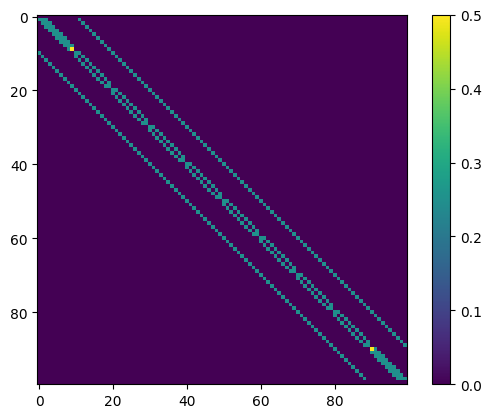

In [8]:
P = np.zeros([N**2, N**2])
p = 1
pi = 0.25

for i in range(N):
    for j in range(N):
        s   = i*N+j
        s_E = i*N+j+1
        s_N = (i-1)*N+j
        s_O = i*N+j-1
        s_S = (i+1)*N+j

        if j < N-1:
            P[s, s_E] = p*pi
        else:
            P[s, s] = p*pi

        if i > 0:
            P[s, s_N] = p*pi
        else:
            P[s, s] = p*pi

        if j > 0:
            P[s, s_O] = p*pi
        else:
            P[s, s] = p*pi

        if i < N-1:
            P[s, s_S] = p*pi
        else:
            P[s, s] = p*pi

        if (i,j) == (0,N-1) or (i,j) == (N-1,0):
            P[s, s] = 2*p*pi

P[0, :] = 0
P[N**2-1, :] = 0

plt.imshow(P)
plt.colorbar()
plt.show()

Reponse partie 1

on a rempli la matrice P avec 0.25 pour chaque direction possible quand l agent tape un bord il reste dans la meme case et on met a zero les lignes des deux etats terminaux

## Partie 2 : Estimation de la politique et de la valeur des états associée

**Coding Task**: Compléter la fonction suivante permettant d'obtenir la fonction de valeur d'état en implémentant la récursion de Bellman.

In [9]:
def get_V(iter, P, R, gamma, show=1):
    V = np.zeros([N**2, 1])

    for n in range(iter):

        V = R + gamma * np.dot(P, V)

        if show and n % 100 == 99:
            clear_output()
            plt.imshow(np.reshape(V, [N, N]))
            plt.title(f'Iteration = {n+1}')
            plt.show()
            sleep(1)

    return V

Maintenant que nous avons toutes nos fonctions, nous pouvons calculer la fonction de valeur d'état en itérant sur notre politique $\pi$ :

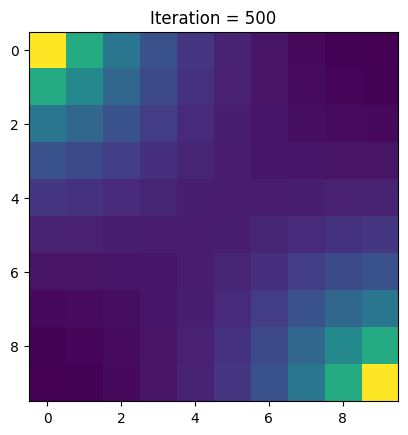

In [10]:
V = np.zeros([N**2,1])
gamma = 1
n_iter = 500

fig = plt.figure()

V = get_V(n_iter,P,R,gamma)


Sans surprise, plus on est proche des points à atteindre, plus la valeur des états est élevée.

**Amélioration de la politique par action gloutonne** : l'évaluation de la fonction de coût associée à notre politique naive nous permet de mettre en évidence une politique $\pi' \geq \pi$. Pour cela il nous faut calculer en tout point quel est le meilleur coup à jouer, c'est à dire la poltique gloutonne ou $greedy$.

**coding task**: Compléter la fonction suivante pour obtenir la greedy policy à partir de la fonction de valeur d'état. La fonction get_next_Vij() renvoie la valeur des états voisins dans un tableau de taille le nombre d'action (donc 4 dans notre cas) avec l'espérance de la valeur d'état après avoir choisi l'action correspondant à l'indice du tableau.

In [11]:
def greedy_policy(V):
    V_2d = np.reshape(V, [N, N])
    pi = np.zeros([N**2, 4])

    for i in range(N):
        for j in range(N):

            if i == 0 and j == 0 or i == N-1 and j == N-1:
                continue

            V_voisin = get_next_Vij(V_2d, i, j)

            args = np.where(V_voisin == np.max(V_voisin))[0]

            pi[i*N+j, args] = 1 / len(args)

    return pi

Nous pouvons enfin afficher la valeur de la politique pour ce griddworld

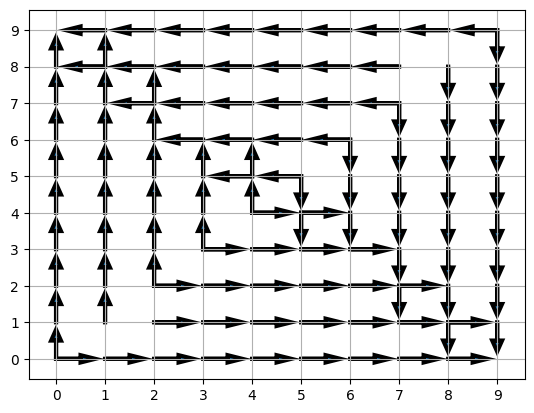

In [12]:
pi = greedy_policy(V)
plot_pi(pi)

Reponse partie 2

avec la formule de Bellman on calcule la valeur de chaque case on voit que les cases proches des coins ont une meilleure valeur et la politique gloutonne choisit juste le voisin qui a la plus grande valeur

## Partie 3 : Maximisation de la politique

Dans le cas précédent, tout l'espace était exploré, conduisant à découvrir la politique optimale après une seule itération. A présent, nous allons initialiser notre politique en faisant le choix d'aller toujours à l'est puis améliorer la politique de façon gloutonne une fois la fonction de valeur estimée.

**coding task** : compléter le code suivant pour permettre d'alterner entre calcul de la fonction de valeur d'état et optimisation de la politique de façon à converger vers la politique idéale.

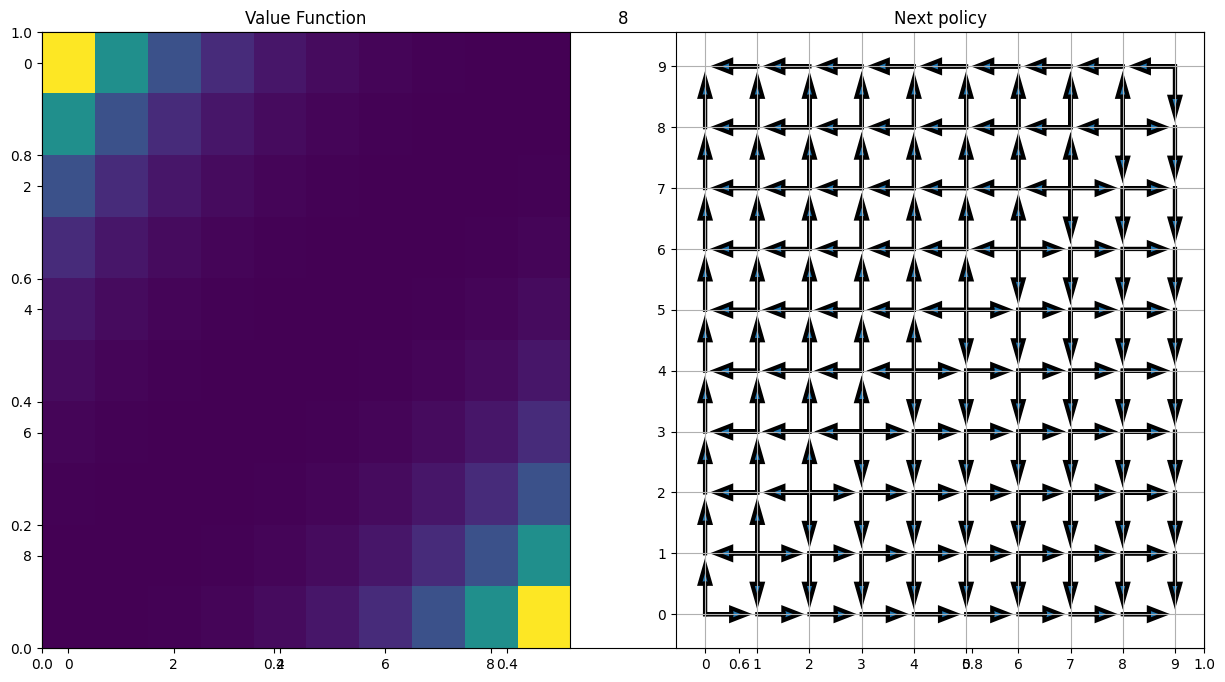

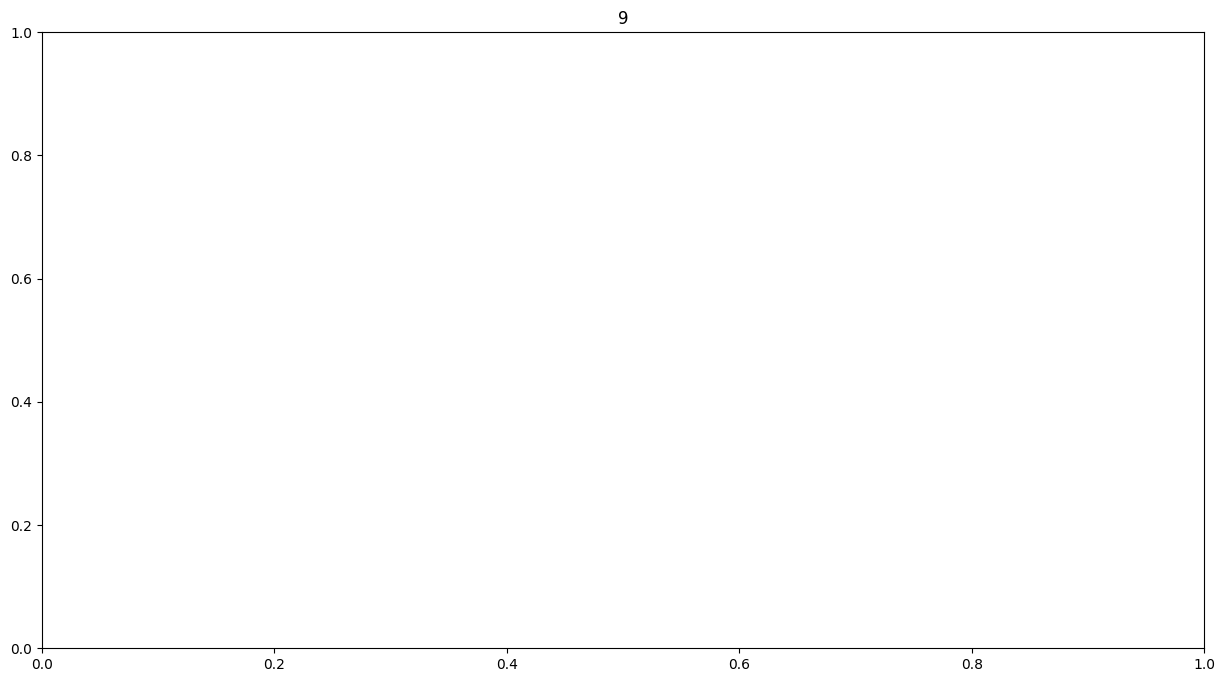

In [13]:
iter_total = 10
iter_policy = 100
show = 1
show_every = 1
gamma = .5

plt.rcParams['figure.figsize'] = [15, 8]

P_pi = get_Ppi([1, 0, 0, 0])

for i in range(iter_total):

    V = get_V(iter_policy, P_pi, R, gamma, show=0)
    pi = greedy_policy(V)
    P_pi = get_Ppi(pi)

    if show and i % show_every == 0:
        clear_output()

        ax = plt.subplot(121)
        plt.imshow(np.reshape(V, [N, N]), aspect="auto")
        ax.set_title('Value Function')

        ax = plt.subplot(122)
        plot_pi(pi)
        ax.set_title('Next policy')

        plt.show()
        plt.title(i)
        sleep(4)

Reponse partie 3

meme en commencant avec une politique qui va toujours a l est le fait d alterner entre calcul de V et politique gloutonne fait converger vers la politique optimale en quelques iterations

## Partie 4 : Labyrinthe

A présent évaluons la valeur des différents états ainsi que la politique optimale pour un labyrinthe. Le labyrinthe est donné par la matrice suivante :

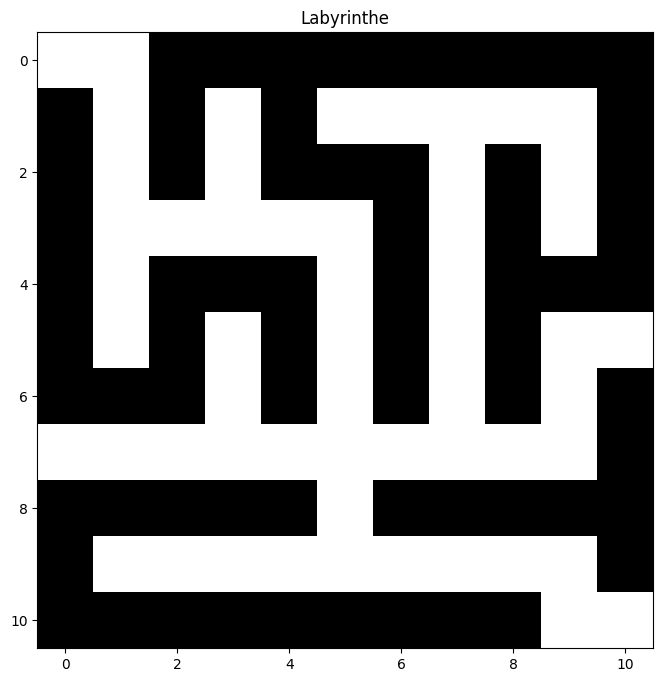

In [15]:
maze =   np.array([[0,0,1,1,1,1,1,1,1,1,1],
                  [1,0,1,0,1,0,0,0,0,0,1],
                  [1,0,1,0,1,1,1,0,1,0,1],
                  [1,0,0,0,0,0,1,0,1,0,1],
                  [1,0,1,1,1,0,1,0,1,1,1],
                  [1,0,1,0,1,0,1,0,1,0,0],
                  [1,1,1,0,1,0,1,0,1,0,1],
                  [0,0,0,0,0,0,0,0,0,0,1],
                  [1,1,1,1,1,0,1,1,1,1,1],
                  [1,0,0,0,0,0,0,0,0,0,1],
                  [1,1,1,1,1,1,1,1,1,0,0]])

N = maze.shape[0]

plt.figure(figsize=(8, 8))
plt.imshow(maze, cmap="binary")
plt.title("Labyrinthe")
plt.show()

**À vous de jouer !**

À vous de réécrire les matrices de transition et de récompense pour ce nouveau problème.

1. Matrice de récompense R


In [16]:
N = maze.shape[0]

R = -np.ones([N**2, 1])

for i in range(N):
    for j in range(N):
        s = i*N+j

        if maze[i, j] == 1:
            R[s] = 0

R[N**2-1] = 0

print(R.reshape(N, N))

[[-1. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  0. -1.  0. -1. -1. -1. -1. -1.  0.]
 [ 0. -1.  0. -1.  0.  0.  0. -1.  0. -1.  0.]
 [ 0. -1. -1. -1. -1. -1.  0. -1.  0. -1.  0.]
 [ 0. -1.  0.  0.  0. -1.  0. -1.  0.  0.  0.]
 [ 0. -1.  0. -1.  0. -1.  0. -1.  0. -1. -1.]
 [ 0.  0.  0. -1.  0. -1.  0. -1.  0. -1.  0.]
 [-1. -1. -1. -1. -1. -1. -1. -1. -1. -1.  0.]
 [ 0.  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.]
 [ 0. -1. -1. -1. -1. -1. -1. -1. -1. -1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0. -1.  0.]]


2. Matrice de transition P

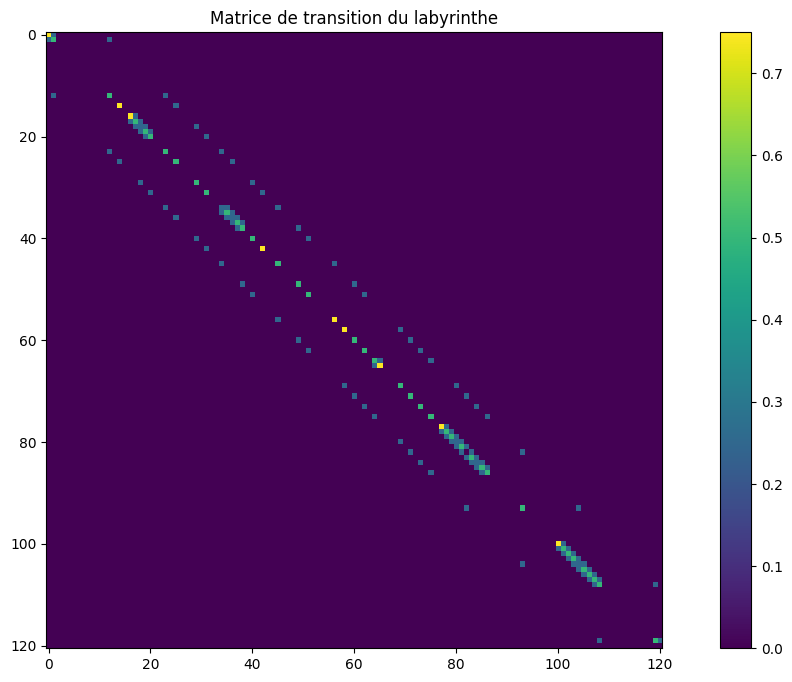

In [17]:
P = np.zeros([N**2, N**2])

p = 1
pi = 0.25

for i in range(N):
    for j in range(N):

        s = i*N+j
        s_E = i*N+j+1
        s_N = (i-1)*N+j
        s_O = i*N+j-1
        s_S = (i+1)*N+j

        # Ignorer les murs
        if maze[i, j] == 1:
            continue

        # Est
        if j < N-1 and maze[i, j+1] == 0:
            P[s, s_E] = p*pi
        else:
            P[s, s] += p*pi

        # Nord
        if i > 0 and maze[i-1, j] == 0:
            P[s, s_N] = p*pi
        else:
            P[s, s] += p*pi

        # Ouest
        if j > 0 and maze[i, j-1] == 0:
            P[s, s_O] = p*pi
        else:
            P[s, s] += p*pi

        # Sud
        if i < N-1 and maze[i+1, j] == 0:
            P[s, s_S] = p*pi
        else:
            P[s, s] += p*pi

# Etat terminal
P[N**2-1, :] = 0

plt.imshow(P)
plt.colorbar()
plt.title("Matrice de transition du labyrinthe")
plt.show()

Évaluation de la fonction de valeur

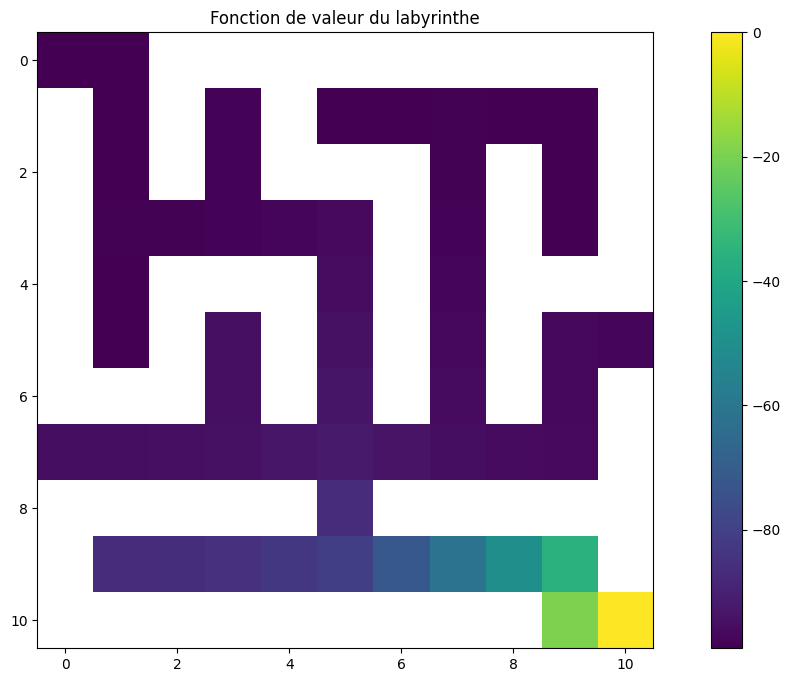

In [18]:
gamma = 0.99

V = get_V(1000, P, R, gamma, show=0)

plt.imshow(
    np.ma.masked_where(maze == 1, V.reshape(N, N)),
    cmap="viridis"
)

plt.colorbar()
plt.title("Fonction de valeur du labyrinthe")
plt.show()

Politique optimale du labyrinthe

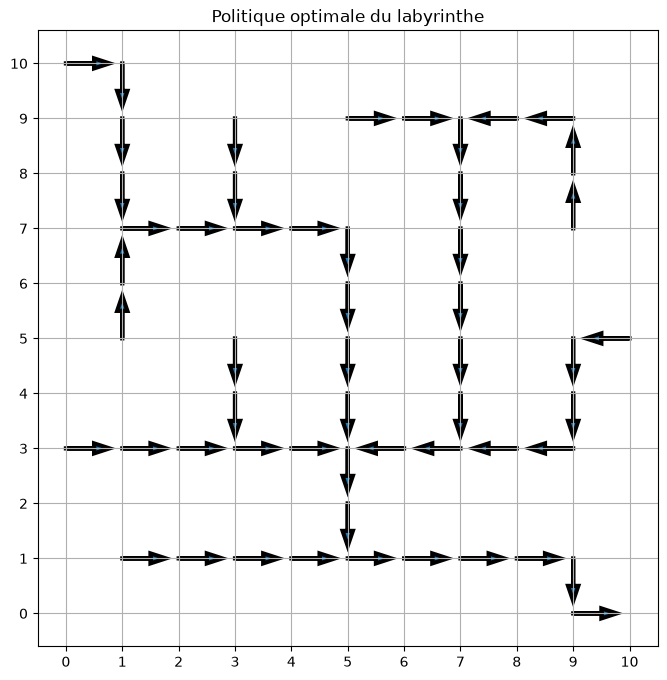

In [ ]:
V_2d = V.reshape(N, N)
pi_maze = np.zeros([N**2, 4])

for i in range(N):
    for j in range(N):
        if maze[i, j] == 1 or (i == N-1 and j == N-1):
            continue
        v_E = V_2d[i, j+1] if j < N-1 and maze[i, j+1] == 0 else -1e6
        v_N = V_2d[i-1, j] if i > 0 and maze[i-1, j] == 0 else -1e6
        v_O = V_2d[i, j-1] if j > 0 and maze[i, j-1] == 0 else -1e6
        v_S = V_2d[i+1, j] if i < N-1 and maze[i+1, j] == 0 else -1e6
        voisins = np.array([v_E, v_N, v_O, v_S])
        best = np.where(voisins == np.max(voisins))[0]
        pi_maze[i*N+j, best] = 1 / len(best)

plt.figure(figsize=(8, 8))
plot_pi(pi_maze)
plt.title("Politique optimale du labyrinthe")
plt.show()

Reponse partie 4

dans le labyrinthe on ignore les murs et l agent reste sur place s il essaie d aller dans un mur apres calcul de V la valeur augmente en approchant la sortie en bas a droite et la politique gloutonne trouve bien le chemin jusqu a la sortie